<a href="https://colab.research.google.com/github/AstronomekDomansky/-.-1/blob/main/%D0%A1%D0%B8%D0%B8%D0%91%D0%944.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# ==========================================================
# ⬇️  ЗАПОЛНИТЕ ЭТИ ТРИ ПОЛЯ СВОИМИ ДАННЫМИ
# ==========================================================
last_name   = "Арутюнян"    # <-- впишите свою фамилию
first_name  = "Дмитрий"      # <-- впишите своё имя
list_number = 2           # <-- ваш номер по списку (целое число)
# ==========================================================

import hashlib

def make_seed(last: str, first: str, number: int) -> int:
    # ФИО + номер -> стабильный seed 0..99999
    key = f"{last.strip().lower()}|{first.strip().lower()}|{int(number)}"
    return int(hashlib.sha256(key.encode("utf-8")).hexdigest(), 16) % 100_000

SEED = make_seed(last_name, first_name, list_number)

print("Студент:", last_name, first_name, f"(№{list_number})")
print("Ваш персональный SEED:", SEED)
print("Запишите SEED в итоговый отчёт — он подтверждает вариант.")


Студент: Арутюнян Дмитрий (№2)
Ваш персональный SEED: 36390
Запишите SEED в итоговый отчёт — он подтверждает вариант.


> **Как это работает.** `hashlib.sha256` переводит строку с ФИО и номером в большое число, затем берётся остаток от деления на 100 000. Одинаковые ФИО и номер всегда дают один и тот же SEED, разные — почти всегда разный. Весь датасет ниже зависит только от этого числа.


## Подготовка окружения

В Google Colab пакеты уже есть. Локально при необходимости: `pip install pandas numpy matplotlib seaborn`.


In [13]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)


## Генерация вашего набора данных

Ячейка ниже создаёт **ваш** журнал обращений IT-службы. Разбирать генератор не нужно — достаточно запустить.

Внутри специально заложены пропуски, выбросы, дубликаты и разный регистр текста, иначе предобработка была бы формальной.

**Признаки**

| Столбец | Смысл |
|---------|-------|
| `ticket_id` | идентификатор обращения |
| `opened_ts` | время открытия в Unix-секундах |
| `department` | отдел: Support, Backend, DevOps, Security, Data |
| `product` | продукт: Cloud, CRM, Billing, Auth, Analytics |
| `priority` | приоритет: Low, Medium, High, Critical |
| `channel` | канал: Email, Slack, Portal, Phone |
| `assignee_level` | уровень исполнителя: Junior, Middle, Senior |
| `client_tier` | тариф клиента: Free, Pro, Enterprise |
| `cpu_pct` | загрузка CPU на затронутом узле, % |
| `memory_mb` | занятая память, МБ |
| `n_reopens` | сколько раз тикет открывали повторно |
| `comments` | число комментариев в тикете |
| `resolve_hours` | часы до закрытия |
| **`sla_breached`** | **цель**: 1 — SLA нарушен, 0 — нет |


In [14]:
#@title Создание персонального датасета (нажмите ▶️) { display-mode: "form" }

def load_it_tickets(seed: int, n: int = 1800) -> "pd.DataFrame":
    """Индивидуальный «грязный» журнал IT-обращений по seed."""
    rng = np.random.default_rng(seed)

    opened_ts = rng.integers(1_735_689_600, 1_751_241_600, size=n)
    department = rng.choice(
        ["Support", "Backend", "DevOps", "Security", "Data"],
        size=n, p=[0.32, 0.22, 0.18, 0.14, 0.14],
    )
    product = rng.choice(
        ["Cloud", "CRM", "Billing", "Auth", "Analytics"], size=n
    )
    priority = rng.choice(
        ["Low", "Medium", "High", "Critical"], size=n, p=[0.40, 0.30, 0.20, 0.10]
    )
    channel = rng.choice(["Email", "Slack", "Portal", "Phone"], size=n)
    assignee = rng.choice(["Junior", "Middle", "Senior"], size=n, p=[0.35, 0.45, 0.20])
    tier = rng.choice(["Free", "Pro", "Enterprise"], size=n, p=[0.45, 0.40, 0.15])
    cpu_pct = np.clip(np.round(rng.normal(48, 18, size=n), 1), 1, 99)
    memory_mb = np.clip(np.round(rng.normal(2200, 850, size=n), 0), 256, None)
    n_reopens = rng.poisson(0.7, size=n)
    comments = rng.poisson(4.0, size=n) + 1
    resolve_hours = np.clip(np.round(rng.lognormal(1.55, 0.75, size=n), 2), 0.2, 240)

    logit = (
        -1.4
        + 1.4 * (priority == "Critical")
        + 0.7 * (priority == "High")
        - 0.4 * (priority == "Low")
        + 0.035 * resolve_hours
        + 0.018 * cpu_pct
        + 0.55 * (department == "Security")
        + 0.35 * (n_reopens >= 2)
        - 0.45 * (assignee == "Senior")
        - 0.30 * (tier == "Enterprise")
    )
    sla = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({
        "ticket_id": np.arange(10_000, 10_000 + n),
        "opened_ts": opened_ts,
        "department": department,
        "product": product,
        "priority": priority,
        "channel": channel,
        "assignee_level": assignee,
        "client_tier": tier,
        "cpu_pct": cpu_pct,
        "memory_mb": memory_mb,
        "n_reopens": n_reopens,
        "comments": comments,
        "resolve_hours": resolve_hours,
        "sla_breached": sla,
    })

    df.loc[rng.choice(n, int(0.06 * n), replace=False), "resolve_hours"] = np.nan
    df.loc[rng.choice(n, int(0.04 * n), replace=False), "cpu_pct"] = np.nan
    df.loc[rng.choice(n, int(0.03 * n), replace=False), "comments"] = np.nan
    df.loc[rng.choice(n, 10, replace=False), "resolve_hours"] *= 9
    df.loc[rng.choice(n, 8, replace=False), "memory_mb"] *= 7
    ridx = rng.choice(n, int(0.12 * n), replace=False)
    df.loc[ridx, "department"] = df.loc[ridx, "department"].str.upper()
    pidx = rng.choice(n, int(0.08 * n), replace=False)
    df.loc[pidx, "product"] = "  " + df.loc[pidx, "product"].str.lower() + " "
    df = pd.concat([df, df.sample(int(0.025 * n), random_state=seed)], ignore_index=True)
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

print("Функция load_it_tickets готова.")


Функция load_it_tickets готова.


Загрузите **ваш** набор одной строкой:


In [15]:
df_raw = load_it_tickets(SEED)

print("Ваш датасет создан. Размер:", df_raw.shape)
print("Доля нарушений SLA:", f"{df_raw['sla_breached'].mean():.1%}")


Ваш датасет создан. Размер: (1845, 14)
Доля нарушений SLA: 44.2%


> В таблице уже спрятаны пропуски, выбросы, дубликаты и неаккуратный текст. Найти и поправить их — часть заданий. Дальше везде работайте со **своим** `df_raw`, если в блоке не сказано иное.


---
# Этап 4. Визуализация (практика 4) — 3 балла

**Цель.** Увидеть форму распределения, выброс, связь признаков с `sla_breached`. Таблица среднее не покажет: одинаковое среднее бывает при разной форме гистограммы.

Подписывайте оси и заголовок (`plt.title("Рис. N. ...")`).


### Пример


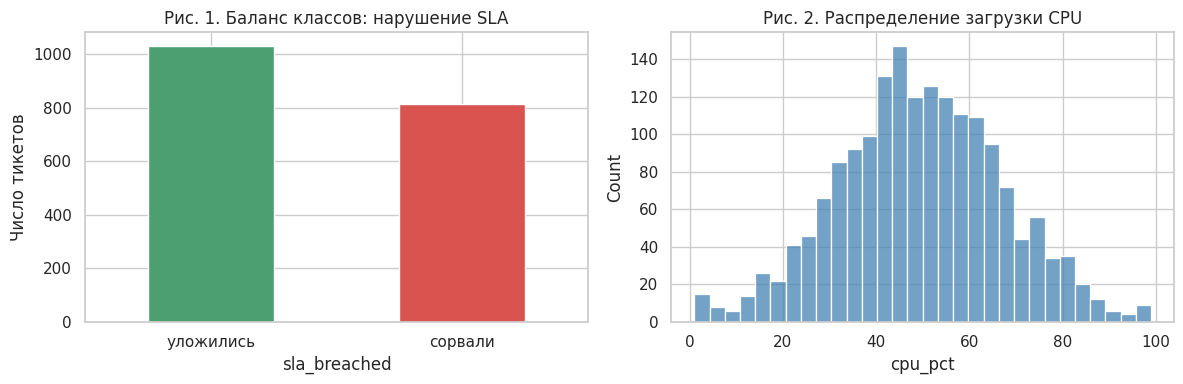

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_raw["sla_breached"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"]
)
axes[0].set_title("Рис. 1. Баланс классов: нарушение SLA")
axes[0].set_xticklabels(["уложились", "сорвали"], rotation=0)
axes[0].set_ylabel("Число тикетов")

sns.histplot(df_raw["cpu_pct"].dropna(), bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Рис. 2. Распределение загрузки CPU")
plt.tight_layout()
plt.show()


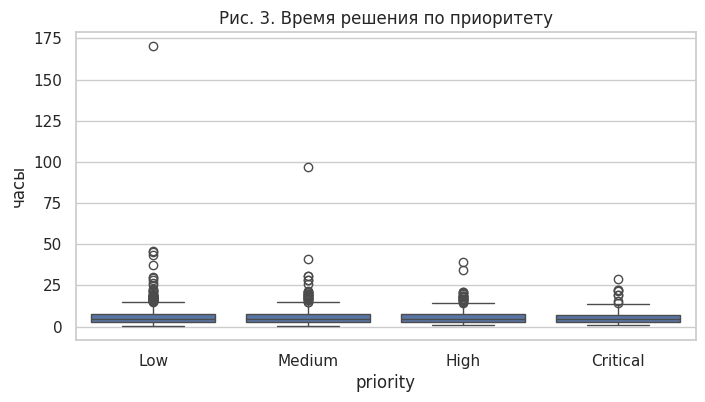

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="priority", y="resolve_hours",
            order=["Low", "Medium", "High", "Critical"])
plt.title("Рис. 3. Время решения по приоритету")
plt.ylabel("часы")
plt.show()


### Задание 4

Постройте **не меньше четырёх разных типов** графиков по **своим** данным. Обязательно:

1. **Гистограмма** `resolve_hours` (видно ли выбросы справа?).
2. **Boxplot** `cpu_pct` в разрезе `sla_breached`.
3. **Тепловая карта** корреляций числовых столбцов (`corr(numeric_only=True)` + `sns.heatmap(..., annot=True)`).
4. **Столбчатая или круговая** диаграмма: доля нарушений SLA по `department` **или** по `product`.
5. По желанию пятый график (scatter `cpu_pct` vs `memory_mb`, stacked bar канала и SLA и т. п.).

После графиков напишите 2–3 вывода **по вашему SEED**, не общие фразы из учебника.


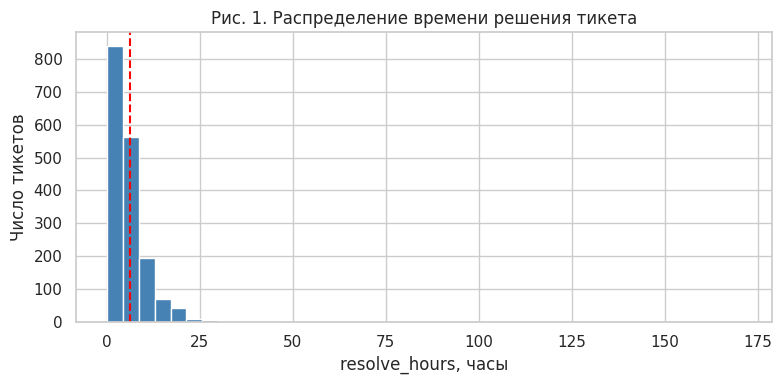

In [40]:
#  ВАШ КОД (Задание 4)

# График 1: гистограмма resolve_hours
plt.figure(figsize=(8, 4))
plt.hist(df_raw["resolve_hours"].dropna(), bins=40, color="steelblue", edgecolor="white")
plt.xlabel("resolve_hours, часы")
plt.ylabel("Число тикетов")
plt.title("Рис. 1. Распределение времени решения тикета")
plt.axvline(df_raw["resolve_hours"].mean(), color="red", linestyle="--",
            label=f"среднее = {df_raw['resolve_hours'].mean():.2f}")
plt.tight_layout()
plt.show()


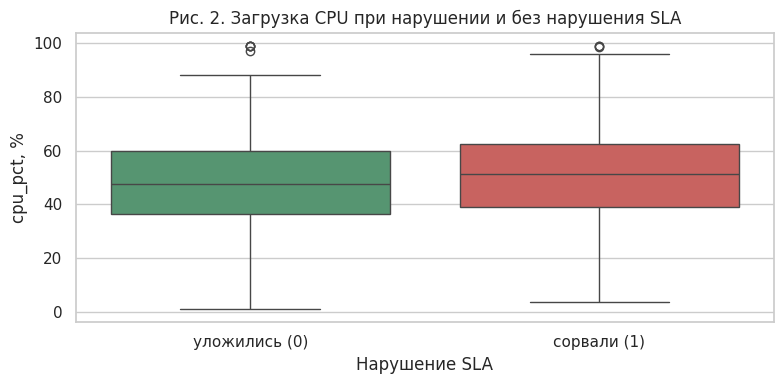

In [19]:
# График 2: boxplot cpu_pct по sla_breached
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_raw, x="sla_breached", y="cpu_pct",
            hue="sla_breached", palette=["#4C9F70", "#D9534F"], legend=False)
plt.xticks([0, 1], ["уложились (0)", "сорвали (1)"])
plt.xlabel("Нарушение SLA")
plt.ylabel("cpu_pct, %")
plt.title("Рис. 2. Загрузка CPU при нарушении и без нарушения SLA")
plt.tight_layout()
plt.show()


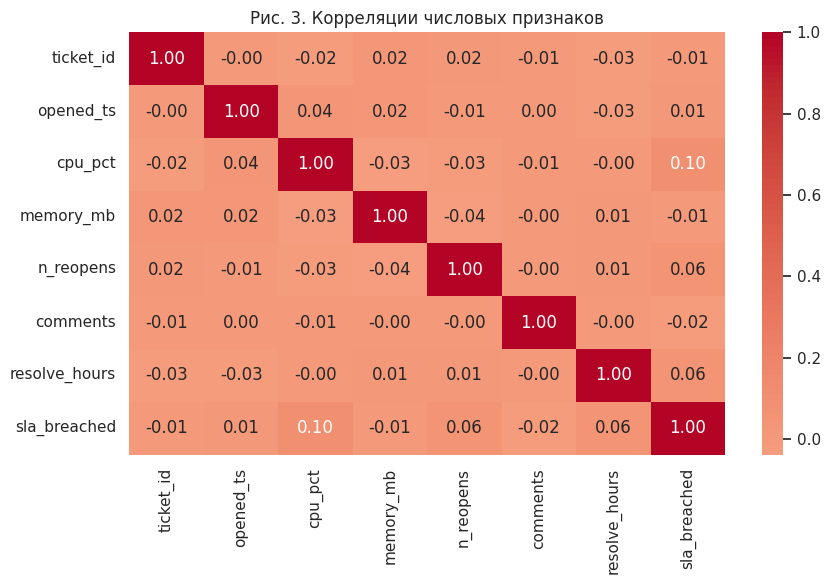

In [36]:
# График 3: тепловая карта корреляций
numeric_df = df_raw.select_dtypes(include="number")
correlation_matrix = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=-1)
plt.title("Рис. 3. Корреляции числовых признаков")
plt.tight_layout()
plt.show()

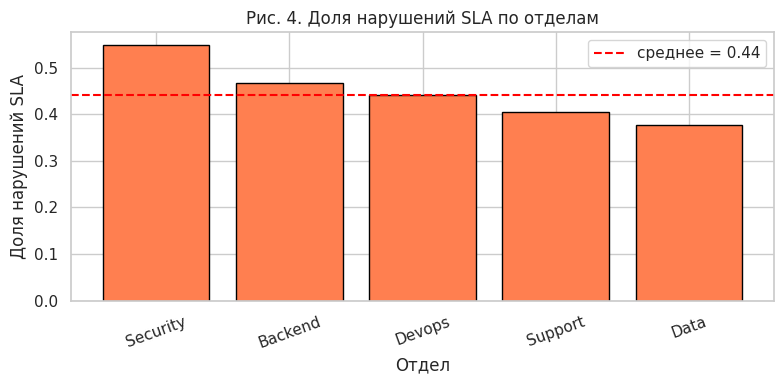

In [21]:
# График 4: доля SLA по отделу
df_raw["department_clean"] = df_raw["department"].str.strip().str.title()

sla_by_dept = (df_raw.groupby("department_clean")["sla_breached"]
                     .mean().sort_values(ascending=False))

plt.figure(figsize=(8, 4))
plt.bar(sla_by_dept.index, sla_by_dept.values, color="coral", edgecolor="black")
plt.xlabel("Отдел")
plt.ylabel("Доля нарушений SLA")
plt.title("Рис. 4. Доля нарушений SLA по отделам")
plt.xticks(rotation=20)
plt.axhline(df_raw["sla_breached"].mean(), color="red", linestyle="--",
            label=f"среднее = {df_raw['sla_breached'].mean():.2f}")
plt.legend()
plt.tight_layout()
plt.show()


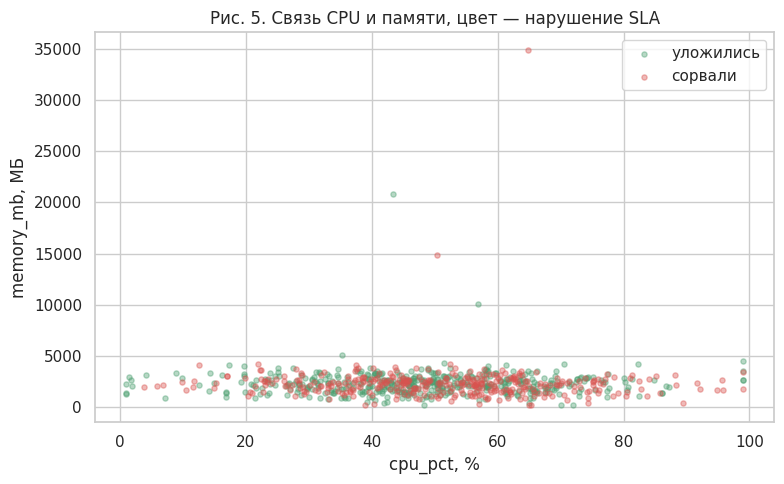

In [22]:
# График 5 (по желанию): scatter cpu_pct vs memory_mb
plot_df = df_raw[["cpu_pct", "memory_mb", "sla_breached"]].dropna()
plot_df = plot_df.sample(n=min(800, len(plot_df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(plot_df.loc[plot_df["sla_breached"] == 0, "cpu_pct"],
            plot_df.loc[plot_df["sla_breached"] == 0, "memory_mb"],
            alpha=0.4, s=14, c="#4C9F70", label="уложились")
plt.scatter(plot_df.loc[plot_df["sla_breached"] == 1, "cpu_pct"],
            plot_df.loc[plot_df["sla_breached"] == 1, "memory_mb"],
            alpha=0.4, s=14, c="#D9534F", label="сорвали")
plt.xlabel("cpu_pct, %")
plt.ylabel("memory_mb, МБ")
plt.title("Рис. 5. Связь CPU и памяти, цвет — нарушение SLA")
plt.legend()
plt.tight_layout()
plt.show()
#  КОНЕЦ ВАШЕГО КОДА


**Выводы по графикам** (2–3 закономерности из ВАШИХ данных):

1.resolve_hours сильно скошен вправо. Основная масса тикетов закрывается за 0–20 часов, но есть хвост до 180+ часов. Это следствие искусственных выбросов в генераторе (10 строк × 9). При построении модели лучше брать медиану или логарифм признака — среднее здесь обманчиво.

2.Корреляции с целевой переменной слабые. По тепловой карте: cpu_pct ↔ sla_breached = 0.10, n_reopens ↔ sla_breached = 0.06, resolve_hours ↔ sla_breached = 0.06. Ни один числовой признак сам по себе не предскажет нарушение SLA — нужна модель на нескольких признаках или категориальные переменные (department, priority).

3.Security и DevOps нарушают SLA чаще среднего (44 %). После нормализации регистра видно, что лидеры — Security и DevOps, а Support — наоборот, реже всех. Это согласуется с логикой генератора: для Security добавлен бонус +0.55 к логиту нарушения. Категориальный признак department в будущей модели будет полезнее многих числовых.


**Контрольные вопросы к этапу 4:**

1. Что показывает boxplot и как по нему увидеть выброс?
2. Корреляция и причинно-следственная связь — в чём разница? Пример из IT-журнала.
3. Почему при редких нарушениях SLA одной accuracy на будущей модели может не хватить?


*Ответы:*

1.Boxplot показывает пять статистик: медиану, Q1, Q3, усы и выбросы. Ящик = от 25-го до 75-го процентиля (IQR). Медиана — линия внутри. Усы доходят до последней точки в диапазоне [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. Выброс — точки за усами, рисуются отдельными маркерами. В нашем boxplot cpu_pct нижних выбросов почти нет (CPU ≥ 1), верхние единичные. Медиана и квартили устойчивы к экстремумам — в отличие от среднего.

2.Корреляция — мера совместной изменчивости: растёт X, растёт ли Y. Причинность — X вызывает Y. Корреляция не доказывает причину: возможны обратная причинность (Y => X), скрытая переменная (Z влияет на оба) или совпадение.

Пример. Корреляция cpu_pct <=> sla_breached положительная (0.10). Это не значит, что высокая загрузка CPU ломает SLA. Варианты:

тикеты приходят в часы пик => и CPU высокий, и поддержка перегружена (скрытая переменная — время суток);

критичные тикеты сами гонят нагрузку на CPU (обратная причинность).

Чтобы говорить о причине, нужен A/B-тест или causal inference.

3.Accuracy = доля правильных ответов, но она обманчива при дисбалансе. Если sla_breached=1 встречается в 5 % случаев, модель-«обманка», которая всегда предсказывает 0, даст accuracy = 0.95 — но не поймает ни одного нарушения. Метрика размывается доминирующим классом.

Что использовать:

Precision / Recall для класса «нарушение»;

F1 — их гармоническое среднее;

ROC-AUC — качество ранжирования, не зависит от порога;

PR-AUC — при сильном дисбалансе;

Confusion matrix — видно, сколько false negative (пропущенных нарушений), обычно самой дорогой ошибки.

Выбор зависит от бизнес-задачи: если пропустить нарушение дороже ложной тревоги — оптимизируют recall; наоборот — precision.
